# Modelling 3: Bias-variance trade-off and regularisation
**Input:** the tuned settings from notebook 1. This notebook shows how regularisation strength changes training and validation scores.

In [ ]:
# Make the shared code in src/ importable, wherever the repository folder is
import os, sys
root = os.getcwd()
while not os.path.isdir(os.path.join(root, "src", "mvsa")) and root != os.path.dirname(root):
    root = os.path.dirname(root)
sys.path.insert(0, os.path.join(root, "src"))

from mvsa.modeling import *

state = load_state("run_state")
PRED, GATES, best_fam, best_setup, CFG = (state[k] for k in ("PRED", "GATES", "best_fam", "best_setup", "CFG"))

## B9. Bias-variance trade-off and regularisation
Logistic regression's `C` is the inverse of the L2 penalty: small `C` means strong regularisation and a simpler model.
We sweep `C` far beyond the tuning grid and compare **training** and **validation** macro-F1 (the test set isn't used):
* **Low scores on both** at small `C` suggest high bias (underfitting).
* **A widening gap** between the two at large `C` suggests high variance (overfitting).
* **The best `C`** is where validation macro-F1 peaks, which is what model selection looks for.

          early_train  early_val  late_train  late_val
C                                                     
0.0001          0.709      0.609       0.683     0.601
0.0010          0.806      0.598       0.758     0.627
0.0100          0.893      0.559       0.815     0.619
0.1000          0.962      0.532       0.833     0.593
1.0000          0.990      0.529       0.839     0.575
10.0000         0.991      0.532       0.840     0.583
100.0000        0.991      0.528       0.841     0.576


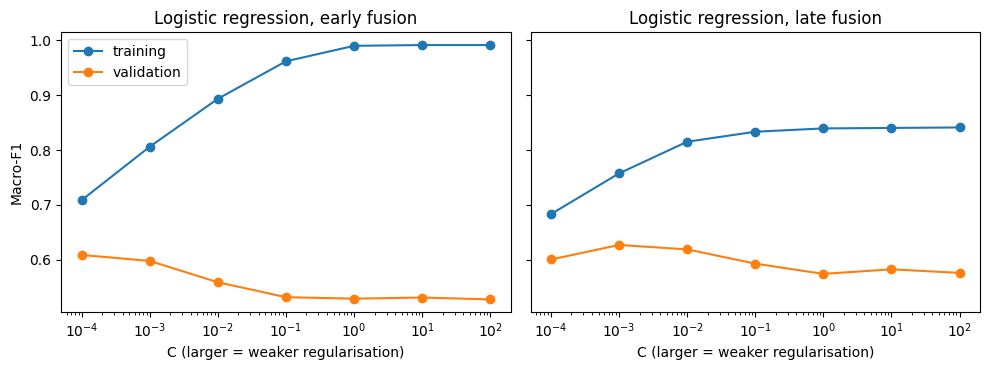

In [13]:
import matplotlib.pyplot as plt

# Wider than the tuning grid, so that both ends of the bias-variance curve can show. Used for this plot only.
C_SWEEP = [1e-4, 1e-3, 1e-2, 1e-1, 1, 10, 100]
trn, vld = D["train"], D["val"]
curve = []
for C in C_SWEEP:
    mods = {k: fit("logreg", {"C": C}, features(trn, k), trn["y"], 0) for k in ("text", "image", "early")}
    w = CFG["logreg"]["late_w"]
    late = lambda d: w * mods["text"].predict_proba(d["text"]) + (1 - w) * mods["image"].predict_proba(d["image"])
    curve.append({"C": C,
                  "early_train": macro_f1(trn["y"], mods["early"].predict_proba(features(trn, "early"))),
                  "early_val":   macro_f1(vld["y"], mods["early"].predict_proba(features(vld, "early"))),
                  "late_train":  macro_f1(trn["y"], late(trn)),
                  "late_val":    macro_f1(vld["y"], late(vld))})
curve = pd.DataFrame(curve).set_index("C")
print(curve.round(3).to_string())
curve.to_csv(os.path.join(OUT_DIR, "bias_variance_curve.csv"))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
for ax, name in zip(axes, ["early", "late"]):
    ax.plot(curve.index, curve[f"{name}_train"], marker="o", label="training")
    ax.plot(curve.index, curve[f"{name}_val"], marker="o", label="validation")
    ax.set_xscale("log"); ax.set_xlabel("C (larger = weaker regularisation)"); ax.set_title(f"Logistic regression, {name} fusion")
axes[0].set_ylabel("Macro-F1"); axes[0].legend()
fig.tight_layout(); fig.savefig(os.path.join(OUT_DIR, "bias_variance_curve.png"), dpi=150); plt.show()

### Tuned hyperparameters per family and input

In [14]:
print(json.dumps(CFG, indent=1))

{
 "logreg": {
  "hp": {
   "text": {
    "C": 0.01
   },
   "image": {
    "C": 0.01
   },
   "early": {
    "C": 0.01
   },
   "early_meta": {
    "C": 0.01
   }
  },
  "late_w": 0.5,
  "gate_C": 0.1
 },
 "linear_svm": {
  "hp": {
   "text": {
    "C": 0.001
   },
   "image": {
    "C": 0.001
   },
   "early": {
    "C": 0.001
   },
   "early_meta": {
    "C": 0.001
   }
  },
  "late_w": 0.5,
  "gate_C": 0.1
 },
 "random_forest": {
  "hp": {
   "text": {
    "min_samples_leaf": 5
   },
   "image": {
    "min_samples_leaf": 5
   },
   "early": {
    "min_samples_leaf": 5
   },
   "early_meta": {
    "min_samples_leaf": 5
   }
  },
  "late_w": 0.0,
  "gate_C": 0.1
 },
 "mlp": {
  "hp": {
   "text": {
    "alpha": 0.1
   },
   "image": {
    "alpha": 0.1
   },
   "early": {
    "alpha": 0.001
   },
   "early_meta": {
    "alpha": 0.001
   }
  },
  "late_w": 0.5,
  "gate_C": 0.1
 }
}
